# Asian Option Delta Estimation using Malliavin Calculus
**Authors:** Mohamed Reda Elaoufir and Alexis Bruneau — MSc project, Université Paris 1 Panthéon-Sorbonne, March 2026. Supervised by Christophe Chorro.

Revised numerical companion to the original report. We compare central finite differences and two Malliavin weights for a continuous call payoff and a discontinuous range digital payoff. All experiments use the original model parameters and a fixed random seed. See `THEORY_CORRECTIONS.md` for corrections to the original report.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import display

T, SIGMA, X, R = 1.0, 0.2, 100.0, 0.03
K1, K2 = 100.0, 110.0
M_LIST = [50, 150, 250]
N_PRICE, N_DELTA = 50_000, 20_000
EPS = 0.2
SEED = 42
DISCOUNT = np.exp(-R*T)


## Simulation and quadrature
Under the risk-neutral measure, $X_t=x\exp((r-\sigma^2/2)t+\sigma B_t)$. Let $A=\int_0^T X_t\,dt$, $J_1=\int_0^T tX_t\,dt$ and $J_2=\int_0^T t^2X_t\,dt$. We use trapezoidal quadrature, not a sum counting both endpoints at full weight. Vectorized batches limit memory usage. All methods share paths within each experiment.

In [2]:
def simulate(n, m, seed=SEED, batch_size=5000):
    rng = np.random.default_rng(seed)
    t = np.linspace(0, T, m+1)
    w = np.ones(m+1) * T/m
    w[[0, -1]] *= 0.5
    out = []
    for start in range(0, n, batch_size):
        k = min(batch_size, n-start)
        b = np.zeros((k, m+1))
        b[:, 1:] = np.cumsum(rng.normal(0, np.sqrt(T/m), (k,m)), axis=1)
        s = X*np.exp((R-0.5*SIGMA**2)*t + SIGMA*b)
        out.append(np.column_stack((s@w, s@(w*t), s@(w*t*t), b[:,-1], s[:,-1])))
    return np.concatenate(out).T

def payoff(a, option):
    if option == 'Call':
        return np.maximum(a-K1, 0)
    if option == 'Range digital':
        return ((a>K1)&(a<K2)).astype(float)
    raise ValueError('Unknown option')

def stats(y):
    mean = np.mean(y)
    var = np.var(y, ddof=1)
    se = np.sqrt(var/len(y))
    return {'Estimate':mean, 'Variance':var, 'SE':se, 'CI low':mean-1.96*se, 'CI high':mean+1.96*se}

OPTIONS = ['Call', 'Range digital']


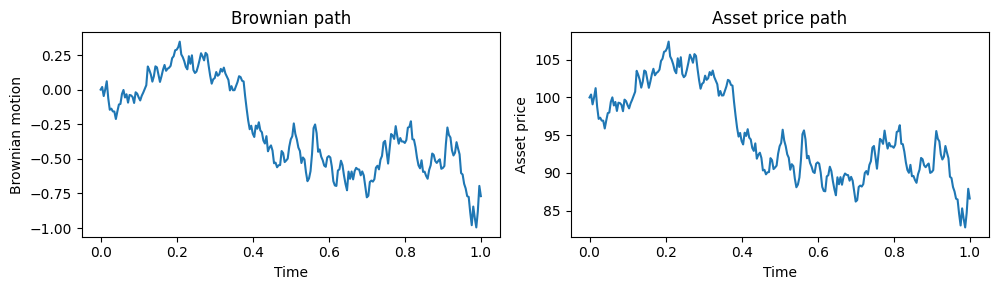

In [3]:
rng = np.random.default_rng(SEED)
t = np.linspace(0,T,251)
b = np.r_[0, np.cumsum(rng.normal(0,np.sqrt(T/250),250))]
s = X*np.exp((R-SIGMA**2/2)*t+SIGMA*b)
fig, ax = plt.subplots(1,2,figsize=(10,3))
ax[0].plot(t,b); ax[0].set(title='Brownian path',xlabel='Time',ylabel='Brownian motion')
ax[1].plot(t,s); ax[1].set(title='Asset price path',xlabel='Time',ylabel='Asset price')
fig.tight_layout(); plt.show()


## A. Pricing and Monte Carlo convergence
The two discounted payoffs are $e^{-rT}(A-K_1)^+$ and $e^{-rT}\mathbf{1}_{\{K_1<A<K_2\}}$. The reported 95% confidence intervals quantify sampling uncertainty, not quadrature bias. The call payoff is continuous and Lipschitz but not differentiable at its strike.

,Option,M,Estimate,Variance,SE,CI low,CI high
0,Call,50,5.294424,59.101102,0.034381,5.227038,5.361810
1,Range digital,50,0.292706,0.198382,0.001992,0.288802,0.296610
2,Call,150,5.305595,60.058022,0.034658,5.237666,5.373524
3,Range digital,150,0.291017,0.197729,0.001989,0.287120,0.294915
4,Call,250,5.291818,59.840521,0.034595,5.224012,5.359624
5,Range digital,250,0.289853,0.197276,0.001986,0.285959,0.293746


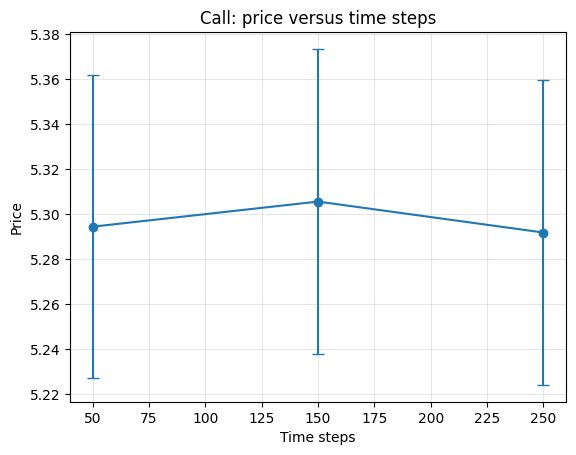

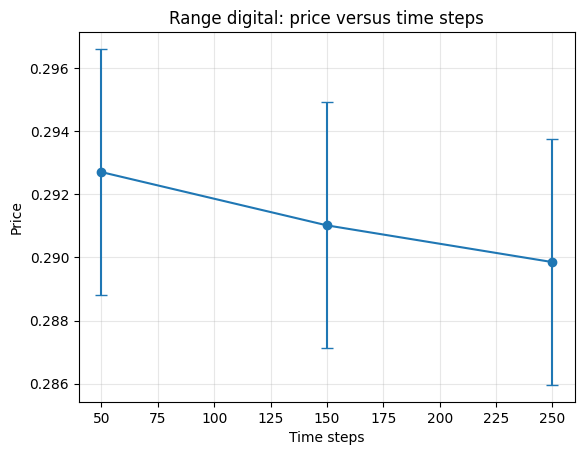

In [4]:
price_rows=[]
for m in M_LIST:
    a = simulate(N_PRICE,m)[0]
    for option in OPTIONS:
        price_rows.append({'Option':option,'M':m,**stats(DISCOUNT*payoff(a,option))})
prices = pd.DataFrame(price_rows)
display(prices)
for option in OPTIONS:
    d=prices[prices.Option==option]
    plt.errorbar(d.M,d.Estimate,yerr=1.96*d.SE,fmt='o-',capsize=4)
    plt.title(f'{option}: price versus time steps'); plt.xlabel('Time steps'); plt.ylabel('Price'); plt.grid(alpha=.3); plt.show()


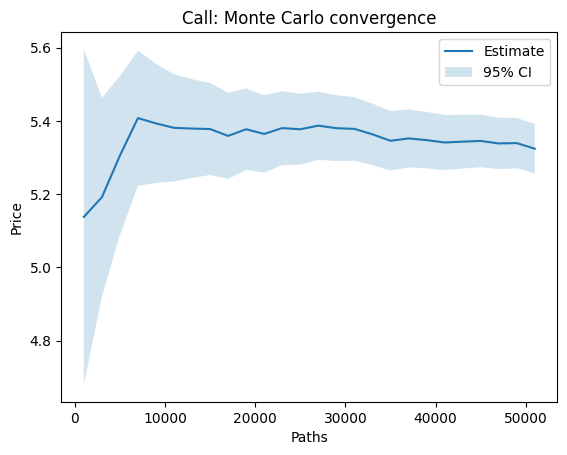

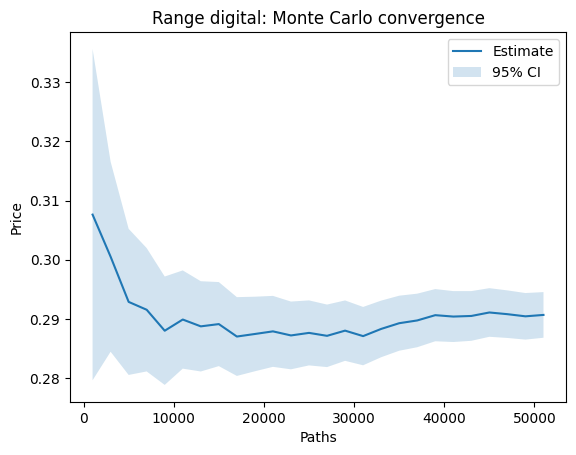

In [5]:
# Nested samples make convergence comparisons easier to interpret.
a = simulate(51_000,250,SEED+1)[0]
n_list = range(1000,51001,2000)
for option in OPTIONS:
    y = DISCOUNT*payoff(a,option)
    d=pd.DataFrame([{'N':n,**stats(y[:n])} for n in n_list])
    plt.plot(d.N,d.Estimate,label='Estimate')
    plt.fill_between(d.N.to_numpy(),d['CI low'].to_numpy(),d['CI high'].to_numpy(),alpha=.2,label='95% CI')
    plt.title(f'{option}: Monte Carlo convergence'); plt.xlabel('Paths'); plt.ylabel('Price'); plt.legend(); plt.show()


## B. Central finite differences
Since $A$ scales linearly with $x$, common random numbers give the pathwise contribution
$$Y_{FD}=e^{-rT}\frac{\Phi(A(1+\varepsilon/x))-\Phi(A(1-\varepsilon/x))}{2\varepsilon}.$$
For the digital, small bumps produce rare nonzero contributions and high variance. For the call, common random numbers avoid that divergence because the payoff is Lipschitz. A larger bump can introduce finite-difference bias.

In [6]:
def finite_difference(a,option,eps=EPS):
    if not 0 < eps < X:
        raise ValueError('Bump must be positive and smaller than spot')
    return DISCOUNT*(payoff(a*(1+eps/X),option)-payoff(a*(1-eps/X),option))/(2*eps)


## C. Malliavin estimators
With $D_tA=\sigma\int_t^T X_s\,ds$, the choice $h=1$ gives $u=A/(\sigma J_1)$. By the divergence product rule,
$$\Pi_1=\delta(u)=\frac{AB_T}{\sigma J_1}+\frac{AJ_2}{J_1^2}-1.$$
The choice $h(t)=X_t$ gives $u(t)=2X_t/(\sigma A)$ and
$$\Pi_2=\frac{2}{\sigma^2}\left(\frac{X_T-x}{A}-r\right)+1.$$
For both weights the discounted Delta contribution is $Y_i=e^{-rT}\Phi(A)\Pi_i/x$. These are continuous-time identities; numerical quadrature introduces discretization error. The digital payoff is handled using the density/smoothing extension of the integration-by-parts representation.

,Option,M,Method,Estimate,Variance,SE,CI low,CI high
0,Call,50,Finite differences,0.563172,0.287754,0.003793,0.555737,0.570606
1,Call,50,Malliavin 1,0.571649,1.828181,0.009561,0.552910,0.590388
2,Call,50,Malliavin 2,0.572752,1.933613,0.009833,0.553480,0.592024
3,Range digital,50,Finite differences,0.008249,0.140026,0.002646,0.003063,0.013435
4,Range digital,50,Malliavin 1,0.009437,0.000976,0.000221,0.009004,0.009870
5,Range digital,50,Malliavin 2,0.009439,0.001053,0.000229,0.008990,0.009889
6,Call,150,Finite differences,0.567409,0.287175,0.003789,0.559982,0.574836
7,Call,150,Malliavin 1,0.566087,1.838561,0.009588,0.547295,0.584879
8,Call,150,Malliavin 2,0.565769,1.918811,0.009795,0.546571,0.584967
9,Range digital,150,Finite differences,0.008734,0.140607,0.002651,0.003537,0.013931


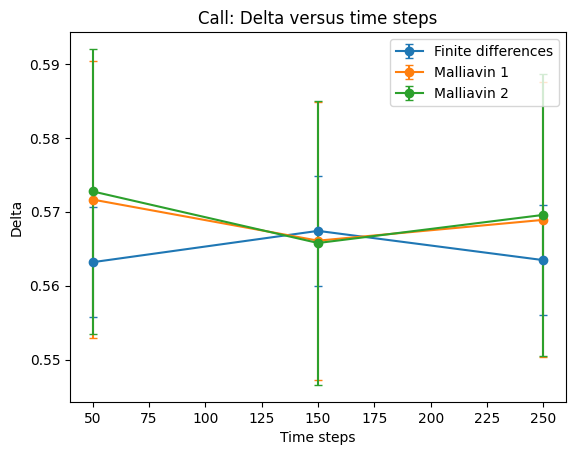

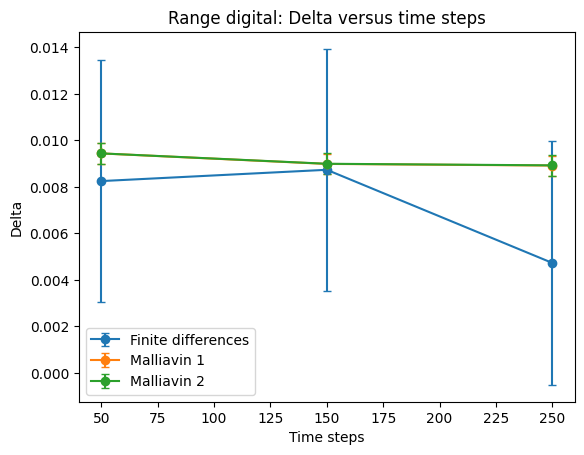

In [7]:
def weights(paths):
    a,j1,j2,bt,st=paths
    pi1=a*bt/(SIGMA*j1)+a*j2/j1**2-1
    pi2=2/SIGMA**2*((st-X)/a-R)+1
    return pi1,pi2

def contributions(paths, option, eps=EPS):
    a=paths[0]
    p1,p2=weights(paths)
    y=DISCOUNT*payoff(a,option)/X
    return {'Finite differences':finite_difference(a,option,eps), 'Malliavin 1':y*p1, 'Malliavin 2':y*p2}

rows=[]
for m in M_LIST:
    paths=simulate(N_DELTA,m,SEED+2)
    for option in OPTIONS:
        for method,y in contributions(paths,option).items():
            rows.append({'Option':option,'M':m,'Method':method,**stats(y)})
results=pd.DataFrame(rows)
display(results)
for option in OPTIONS:
    for method in results.Method.unique():
        d=results[(results.Option==option)&(results.Method==method)]
        plt.errorbar(d.M,d.Estimate,yerr=1.96*d.SE,fmt='o-',capsize=3,label=method)
    plt.title(f'{option}: Delta versus time steps'); plt.xlabel('Time steps'); plt.ylabel('Delta'); plt.legend(); plt.show()


## D. Bump sensitivity and estimator comparison
The bump experiment uses the same paths for every bump. Differences from the smallest bump are not a direct measurement of bias because that reference is itself noisy.

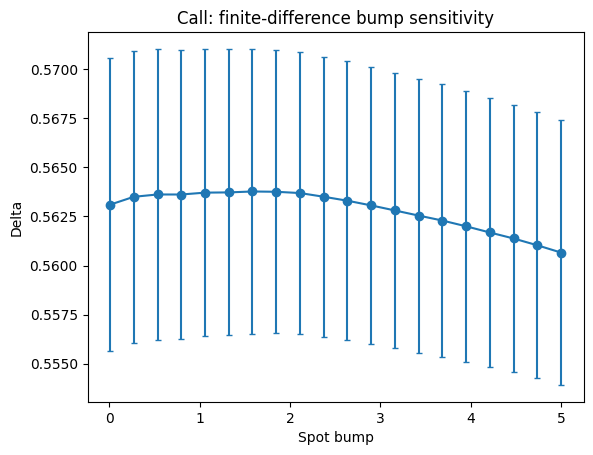

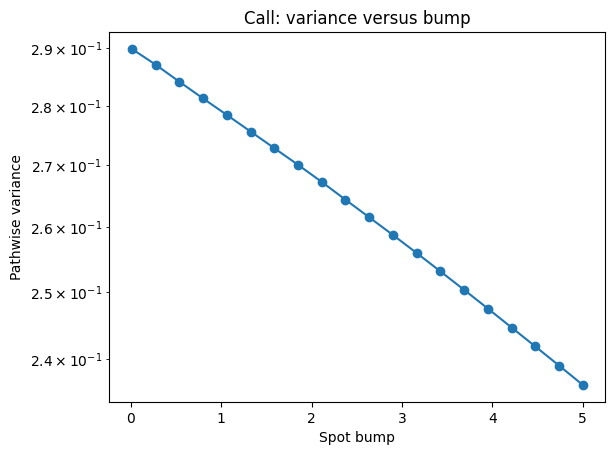

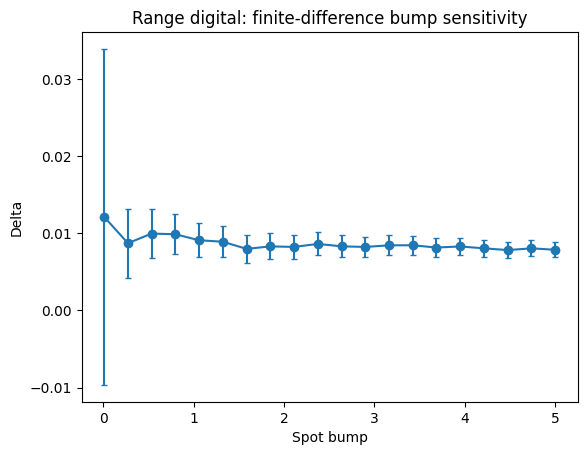

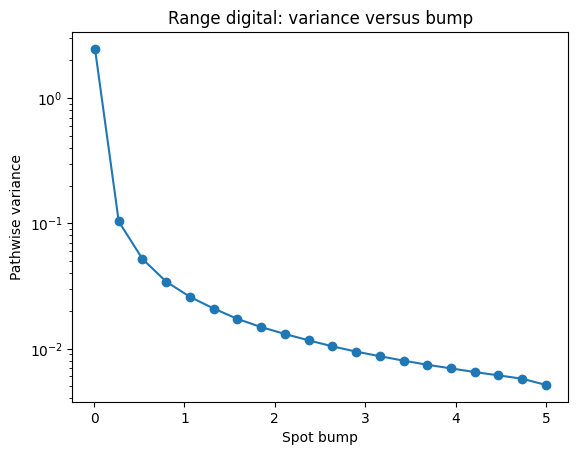

In [8]:
paths=simulate(N_DELTA,250,SEED+2)
for option in OPTIONS:
    d=pd.DataFrame([{'Bump':e,**stats(finite_difference(paths[0],option,e))} for e in np.linspace(.01,5,20)])
    plt.errorbar(d.Bump,d.Estimate,yerr=1.96*d.SE,fmt='o-',capsize=2)
    plt.title(f'{option}: finite-difference bump sensitivity'); plt.xlabel('Spot bump'); plt.ylabel('Delta'); plt.show()
    plt.plot(d.Bump,d.Variance,'o-'); plt.yscale('log'); plt.xlabel('Spot bump'); plt.ylabel('Pathwise variance'); plt.title(f'{option}: variance versus bump'); plt.show()


,Option,M,Method,Estimate,Variance,SE,CI low,CI high,FD variance / method variance
12,Call,250,Finite differences,0.563451,0.287854,0.003794,0.556015,0.570887,1.000000
13,Call,250,Malliavin 1,0.568902,1.803399,0.009496,0.550290,0.587514,0.159618
14,Call,250,Malliavin 2,0.569574,1.901288,0.009750,0.550463,0.588684,0.151400
15,Range digital,250,Finite differences,0.004731,0.143310,0.002677,-0.000516,0.009978,1.000000
16,Range digital,250,Malliavin 1,0.008917,0.000963,0.000219,0.008487,0.009347,148.879394
17,Range digital,250,Malliavin 2,0.008925,0.001026,0.000226,0.008481,0.009369,139.691782


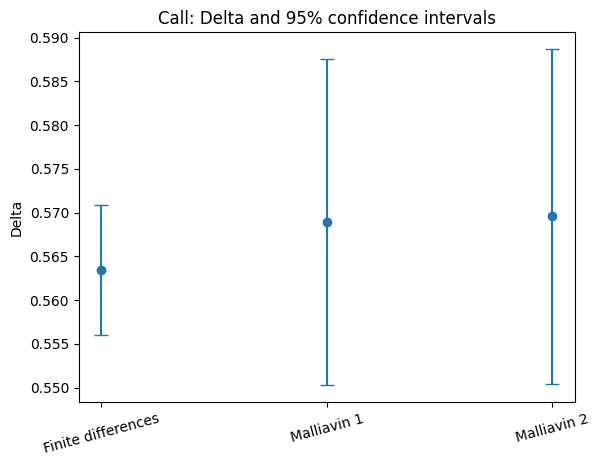

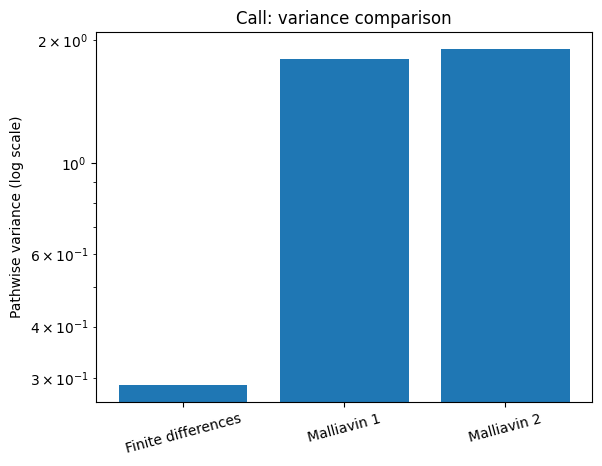

Call
  Malliavin 1: marginal CIs overlap = True; paired difference 95% CI = [-0.010859, 0.021762]
  Malliavin 2: marginal CIs overlap = True; paired difference 95% CI = [-0.010748, 0.022994]


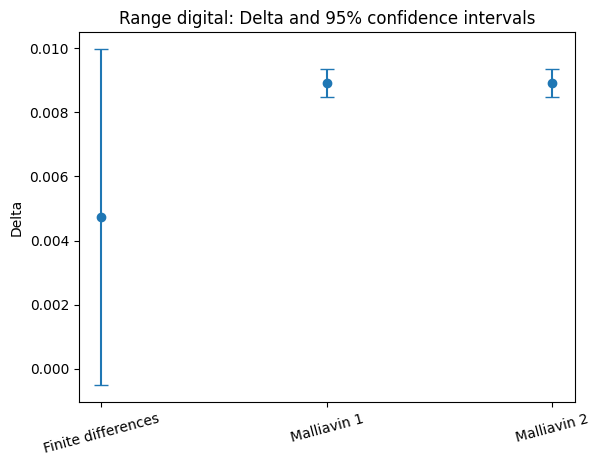

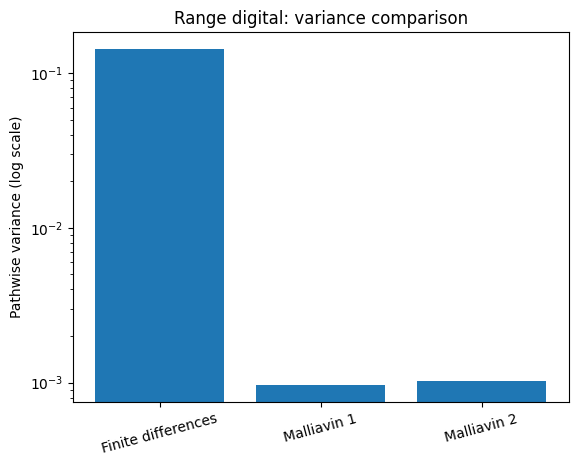

Range digital
  Malliavin 1: marginal CIs overlap = True; paired difference 95% CI = [-0.001108, 0.009479]
  Malliavin 2: marginal CIs overlap = True; paired difference 95% CI = [-0.001100, 0.009488]


In [9]:
comparison=results[results.M==250].copy()
comparison['FD variance / method variance']=comparison.groupby('Option')['Variance'].transform(lambda v:v.iloc[0]/v)
display(comparison)
for option in OPTIONS:
    d=comparison[comparison.Option==option]
    plt.errorbar(d.Method,d.Estimate,yerr=1.96*d.SE,fmt='o',capsize=5)
    plt.title(f'{option}: Delta and 95% confidence intervals'); plt.ylabel('Delta'); plt.xticks(rotation=15); plt.show()
    plt.bar(d.Method,d.Variance); plt.yscale('log'); plt.ylabel('Pathwise variance (log scale)'); plt.title(f'{option}: variance comparison'); plt.xticks(rotation=15); plt.show()
    print(option)
    ys=contributions(paths,option)
    for method in ['Malliavin 1','Malliavin 2']:
        a,b=d.iloc[0],d[d.Method==method].iloc[0]
        overlap=max(a['CI low'],b['CI low']) <= min(a['CI high'],b['CI high'])
        paired=stats(ys[method]-ys['Finite differences'])
        print(f"  {method}: marginal CIs overlap = {overlap}; paired difference 95% CI = [{paired['CI low']:.6f}, {paired['CI high']:.6f}]")


## E. Interpretation and limitations
The call and the range digital illustrate why a variance-reduction method should be chosen for the payoff rather than universally. The comparison above reports actual sample variances and confidence intervals. Overlap alone is not proof of equality; paired differences exploit the shared random paths. Neither sampling intervals nor paired comparisons eliminate discretization or finite-difference bias.

The theoretical Rao–Blackwell improvement is $\Pi^*=\mathbb E[\Pi\mid A]$; since the payoff is measurable with respect to $A$, conditioning reduces the variance of the payoff-weighted contribution whenever it is square-integrable. This is a theoretical result, not a numerically implemented estimator here.